# RGT-Est on your own SEG-Y: RGT, horizons and an RGT-guided LFM

Runs the pretrained RGT-Est model (Dou, Wu, Gao & Bi, 2026) on a SEG-Y exported from RokDoc, and writes the results back as files RokDoc can load:

| Output | File |
|---|---|
| RGT volume (same trace headers as your input) | `<input>_RGT.sgy` (and `<input>_RGT_guided.sgy` if you give horizons) |
| Horizons traced through chosen times at the well | `<input>_horizons.txt` (Inline, Crossline, X, Y, TWT) |
| Velocity model resampled onto the seismic grid (optional) | `<input>_Vint_on_grid.sgy` |
| Low-frequency model (optional, needs a well log): velocity background + well detail along RGT | `<input>_LFM.sgy`, a decimated `<input>_LFM_stepN.sgy`, and `<input>_LFM_velocity_only.sgy` for comparison |

**Before you start**
1. **Runtime → Change runtime type → L4 GPU.**
2. Open the **Files** panel (folder icon, left) and upload:
   - `RGT-Est_CIG-Benchmark.pt` (the pretrained model)
   - your SEG-Y crop
   - *(optional, for horizon guidance)* RokDoc horizon exports (`.txt`: Inline, Crossline, TWT)
   - *(optional)* an interval-velocity SEG-Y in TWT: any extent or sampling, null padding is fine
   - *(optional, for the LFM)* the well log as `.xlsx` or `.csv`: **TWT (ms) in the first column, impedance in the second**. Extra header rows are fine.
3. Check the **Settings** cell, then **Runtime → Run all**.

**Keeping your data private:** this notebook never uploads your data anywhere. But if you use *File → Save a copy in GitHub*, **untick "Include cell outputs"**, or the plots and printed values will be published with the notebook.

## 1. Settings

In [2]:
DATA_FOLDER   = "/content"
MODEL_FILE    = "RGT-Est_CIG-Benchmark.pt"
SEGY_FILE     = "Full_Stack_8_41_CROP_1793889427461.sgy"

# SEG-Y header byte positions for inline / crossline. None = detect automatically.
IL_BYTE, XL_BYTE = None, None

INTERVAL_MS   = (1300, 2300)        # interval of interest (for plots)
WELL_IL, WELL_XL = 1123, 2098       # well location

# Horizon guidance (optional): RokDoc horizon .txt exports in TWT. Empty list = unguided only.
HORIZON_FILES = ["Jubilee.txt", "Ranger.txt"]   # [] = unguided only
USE_GUIDED    = True                # use the guided RGT for the horizon/LFM outputs below

# Horizons: traced through these TWTs at the well, then followed across the survey by the RGT
HORIZON_TIMES_AT_WELL = [1300, 1550, 1800, 2050, 2300]

# Low-frequency model (skipped if WELL_LOG_FILE is empty)
WELL_LOG_FILE = "Norton_3_Export_AI.xlsx"     # column 1 = TWT (ms), column 2 = AI; "" = skip the LFM
LFM_CUTOFF_HZ = 8                   # low-pass cut-off for the log
LFM_TRACE_STEP = 8                  # also write a decimated LFM, every Nth inline and crossline
LFM_TAPER_MS  = 100                 # above/below the log, fade from the well's detail to the velocity background

# Velocity model (optional): interval velocity SEG-Y in TWT. Its extent and sampling can differ from
# the seismic; null-padded traces (zeros, -999.25, ...) are dropped and gaps are interpolated.
VELOCITY_FILE = "Vint_Vint_1793927905561.sgy" # "" = no velocity model
VEL_IL_BYTE, VEL_XL_BYTE = None, None   # None = detect automatically
VEL_MATCH     = "auto"              # "auto", "ilxl" (by inline/crossline headers) or "xy" (by X/Y coordinates)

## 2. Set up: GPU, libraries, files

In [3]:
!pip -q install segyio
import os, glob, torch
print("PyTorch", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0),
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB)")
else:
    print("No GPU found. Go to Runtime → Change runtime type → GPU, then run again.")

import time
RUN_START = time.time()

def find_file(name):
    # Exact name only (in DATA_FOLDER or any subfolder). Never substitutes another file.
    if not name:
        return None
    p = os.path.join(DATA_FOLDER, name)
    if os.path.exists(p):
        return p
    hits = glob.glob(f"/content/**/{name}", recursive=True)
    return hits[0] if hits else None

def list_uploaded(*exts):
    return sorted(os.path.relpath(h, "/content") for e in exts for h in glob.glob(f"/content/**/*{e}", recursive=True)
                  if "/sample_data/" not in h)

MODEL_PATH = find_file(MODEL_FILE)
SEGY_PATH  = find_file(SEGY_FILE)
LOG_PATH   = find_file(WELL_LOG_FILE) if WELL_LOG_FILE else None
VEL_PATH   = find_file(VELOCITY_FILE) if VELOCITY_FILE else None
for label, p, needed in (("model", MODEL_PATH, True), ("SEG-Y", SEGY_PATH, True),
                         ("well log", LOG_PATH, bool(WELL_LOG_FILE)), ("velocity", VEL_PATH, bool(VELOCITY_FILE))):
    if p:        print(f"found    {label:9s} {p}  ({os.path.getsize(p)/1e6:.0f} MB)")
    elif needed: print(f"MISSING  {label}")
    else:        print(f"(no {label} file set: optional, skipped)")
HORIZON_PATHS = []
for h in HORIZON_FILES:
    p = find_file(h)
    print(f"found    horizon   {p}" if p else f"MISSING  horizon {h}")
    if not p:
        txts = [os.path.basename(t) for t in glob.glob("/content/**/*.txt", recursive=True) if "/sample_data/" not in t]
        raise FileNotFoundError(f"Horizon file {h!r} not found. .txt files uploaded: {txts}")
    HORIZON_PATHS.append(p)
if not (MODEL_PATH and SEGY_PATH) or (WELL_LOG_FILE and not LOG_PATH) or (VELOCITY_FILE and not VEL_PATH):
    print("\nFiles currently in the session:")
    print("  SEG-Y:", list_uploaded(".sgy", ".segy", ".SGY", ".SEGY") or "none")
    print("  model:", list_uploaded(".pt") or "none")
    print("  other:", list_uploaded(".txt", ".xlsx", ".csv") or "none")
    raise FileNotFoundError("Upload the missing file(s) in the Files panel, or fix the names in Settings, then run this cell again. "
                            "(Files ending _RGT / _LFM / _Vint_on_grid are outputs from earlier runs, not inputs.)")
for label, p in (("SEG-Y", SEGY_PATH), ("velocity", VEL_PATH)):
    if p and any(tag in os.path.basename(p) for tag in ("_RGT", "_LFM", "_Vint_on_grid")):
        raise ValueError(f"The {label} file {os.path.basename(p)} looks like an OUTPUT of an earlier run, not an input. "
                         "Set the original file name in Settings.")

!git clone -q https://github.com/fergusrssmith/RGT /content/RGT 2>/dev/null || git -C /content/RGT pull -q
import sys
sys.path.insert(0, "/content/RGT/demo")
sys.path.insert(0, "/content/RGT/colab")
import importlib, rgt_lfm as R
importlib.reload(R)

PyTorch 2.11.0+cu130
GPU: NVIDIA L4 (24 GB)
found    model     /content/RGT-Est_CIG-Benchmark.pt  (309 MB)
found    SEG-Y     /content/Full_Stack_8_41_CROP_1793889427461.sgy  (241 MB)
found    well log  /content/Norton_3_Export_AI.xlsx  (0 MB)
found    velocity  /content/Vint_Vint_1793927905561.sgy  (241 MB)
found    horizon   /content/Jubilee.txt
found    horizon   /content/Ranger.txt


<module 'rgt_lfm' from '/content/RGT/colab/rgt_lfm.py'>

## 3. Read the SEG-Y and check the geometry

**Compare the printout with RokDoc's 3D Geometry dialog** (inline/crossline ranges, sample rate, corner coordinates). If they match, the output files will land in the right place.

In [4]:
import numpy as np
import segyio

G = R.read_segy_cube(SEGY_PATH, IL_BYTE, XL_BYTE)
cube, ilines, xlines, samples, dt = G["cube"], G["ilines"], G["xlines"], G["samples"], G["dt"]
il_idx, xl_idx, trace_index, X, Y = G["il_idx"], G["xl_idx"], G["trace_index"], G["X"], G["Y"]
n_tr, il_byte, xl_byte = G["n_tr"], G["il_byte"], G["xl_byte"]
NI, NX, NT = cube.shape

print(f"Header bytes used:  inline {il_byte}, crossline {xl_byte}")
print(f"Inlines:    {ilines[0]} – {ilines[-1]}  ({NI})")
print(f"Crosslines: {xlines[0]} – {xlines[-1]}  ({NX})")
print(f"TWT:        {samples[0]:.0f} – {samples[-1]:.0f} ms, every {dt:g} ms  ({NT} samples)")
print(f"Traces:     {n_tr}  (missing grid nodes: {(trace_index < 0).sum()})")
print("Corner coordinates (inline, crossline → X, Y):")
for i, j in ((0, 0), (0, NX - 1), (NI - 1, 0), (NI - 1, NX - 1)):
    print(f"   {ilines[i]:>6}, {xlines[j]:>6} → {X[i, j]:,.1f}, {Y[i, j]:,.1f}")
print(f"Amplitudes: min {cube.min():.3g}, max {cube.max():.3g}, std {cube.std():.3g}")

if WELL_IL in ilines and WELL_XL in xlines:
    wi, wx = np.searchsorted(ilines, WELL_IL), np.searchsorted(xlines, WELL_XL)
    print(f"Well at inline {WELL_IL}, crossline {WELL_XL} → X {X[wi, wx]:,.1f}, Y {Y[wi, wx]:,.1f}")
else:
    wi = wx = None
    print(f"WARNING: the well (inline {WELL_IL}, crossline {WELL_XL}) is outside this volume.")

Header bytes used:  inline 189, crossline 193
Inlines:    995 – 1250  (256)
Crosslines: 1839 – 2350  (512)
TWT:        1000 – 2596 ms, every 4 ms  (400 samples)
Traces:     131072  (missing grid nodes: 0)
Corner coordinates (inline, crossline → X, Y):
      995,   1839 → 183,053.1, 7,620,382.0
      995,   2350 → 185,449.0, 7,626,303.0
     1250,   1839 → 188,962.1, 7,617,990.5
     1250,   2350 → 191,358.0, 7,623,911.5
Amplitudes: min -6.25e+04, max 5.47e+04, std 3.57e+03
Well at inline 1123, crossline 2098 → X 187,233.6, Y 7,622,182.6


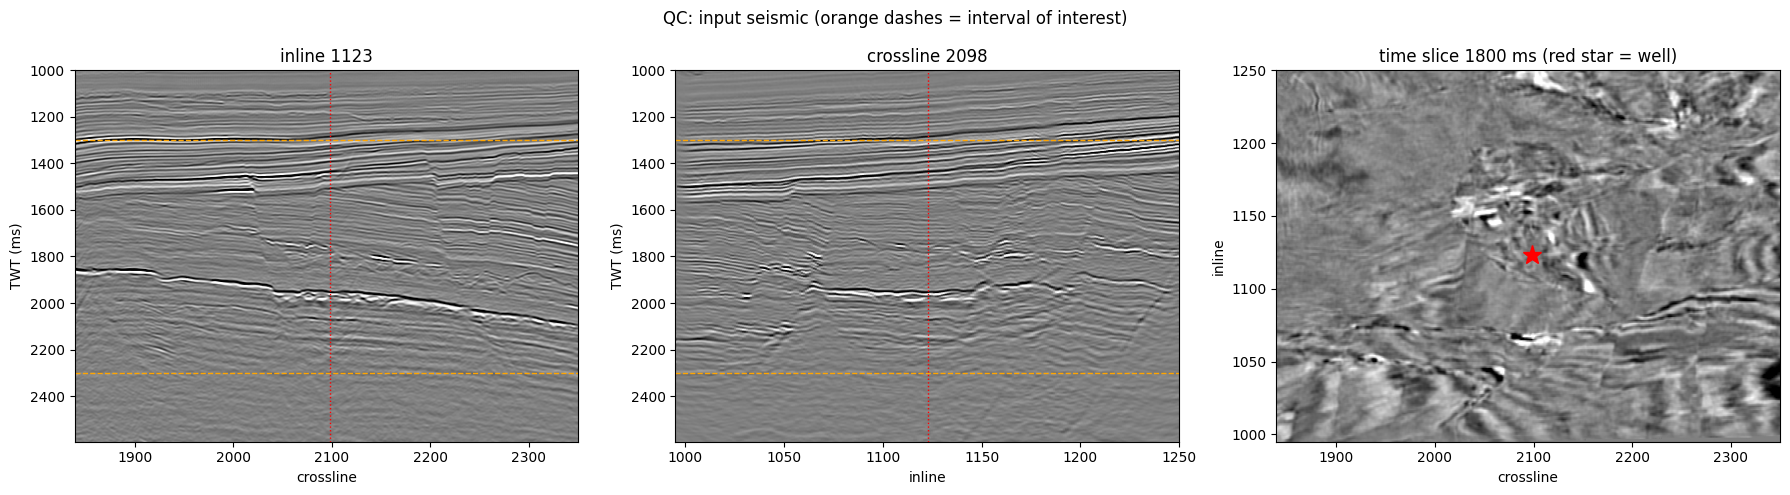

In [5]:
import matplotlib.pyplot as plt

def tidx(ms):
    return int(np.clip(round((ms - samples[0]) / dt), 0, NT - 1))

ci = wi if wi is not None else NI // 2
cx_ = wx if wx is not None else NX // 2
v = np.percentile(np.abs(cube), 99)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cube[ci].T, cmap="gray", aspect="auto", vmin=-v, vmax=v,
               extent=(xlines[0], xlines[-1], samples[-1], samples[0]))
axes[0].set_title(f"inline {ilines[ci]}"); axes[0].set_xlabel("crossline")
axes[1].imshow(cube[:, cx_].T, cmap="gray", aspect="auto", vmin=-v, vmax=v,
               extent=(ilines[0], ilines[-1], samples[-1], samples[0]))
axes[1].set_title(f"crossline {xlines[cx_]}"); axes[1].set_xlabel("inline")
for ax in axes[:2]:
    ax.set_ylabel("TWT (ms)")
    for t in INTERVAL_MS: ax.axhline(t, color="orange", lw=1, ls="--")
axes[0].axvline(xlines[cx_], color="red", lw=1, ls=":"); axes[1].axvline(ilines[ci], color="red", lw=1, ls=":")
tm = sum(INTERVAL_MS) / 2
axes[2].imshow(cube[:, :, tidx(tm)], cmap="gray", aspect="auto", vmin=-v, vmax=v, origin="lower",
               extent=(xlines[0], xlines[-1], ilines[0], ilines[-1]))
axes[2].plot(WELL_XL, WELL_IL, "r*", ms=14)
axes[2].set_title(f"time slice {tm:.0f} ms (red star = well)"); axes[2].set_xlabel("crossline"); axes[2].set_ylabel("inline")
fig.suptitle("QC: input seismic (orange dashes = interval of interest)"); fig.tight_layout(); plt.show()

## 3b. Load the guidance horizons (skipped if `HORIZON_FILES` is empty)

Points are matched to the crop by their inline/crossline numbers. Anything outside the crop (or outside its TWT window), and null values, are dropped.

Jubilee: 179,456 points in file, 131,072 on the crop (100% of traces), TWT 1743 – 2209 ms
Ranger: 179,456 points in file, 131,072 on the crop (100% of traces), TWT 1365 – 1637 ms
Ranger → Jubilee: median gap 462 ms, crossing/touching on 0.0% of traces


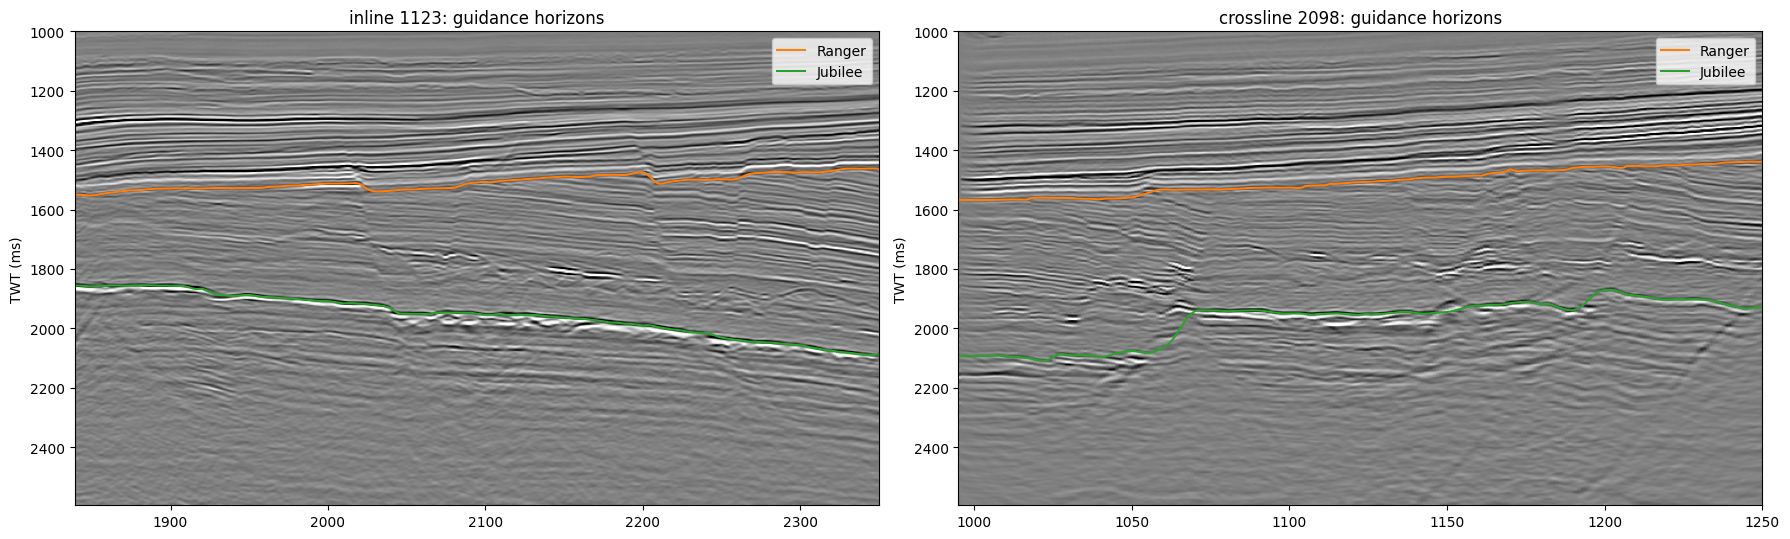

In [6]:
import re

HZ = []
for path in HORIZON_PATHS:
    name, ztype, rows = os.path.splitext(os.path.basename(path))[0], None, []
    with open(path, errors="ignore") as fh:
        for line in fh:
            m = re.match(r'\s*Horizon\s+"(.+?)"', line)
            if m: name = m.group(1)
            if "Z Type" in line: ztype = line.split(":")[-1].strip()
            parts = line.replace(",", " ").split()
            if len(parts) >= 3:
                try: rows.append([float(v) for v in parts[:3]])
                except ValueError: pass
    a = np.array(rows, dtype=float)
    if ztype and ztype.upper() != "TWT":
        print(f"WARNING: {name} has Z type {ztype!r}, but the seismic is in TWT.")
    hil, hxl, hz = np.round(a[:, 0]), np.round(a[:, 1]), a[:, 2]
    ok = np.isfinite(hz) & (hz > -999) & np.isin(hil, ilines) & np.isin(hxl, xlines) \
         & (hz >= samples[0]) & (hz <= samples[-1])
    t = np.full((NI, NX), np.nan)
    t[np.searchsorted(ilines, hil[ok]), np.searchsorted(xlines, hxl[ok])] = hz[ok]
    if not np.isfinite(t).any():
        print(f"{name}: no points fall on the crop (inline/crossline/TWT): skipped."); continue
    HZ.append(dict(name=name, t=t))
    print(f"{name}: {len(a):,} points in file, {np.isfinite(t).sum():,} on the crop "
          f"({100*np.isfinite(t).mean():.0f}% of traces), TWT {np.nanmin(t):.0f} – {np.nanmax(t):.0f} ms")

HZ.sort(key=lambda h: np.nanmean(h["t"]))                       # shallow → deep
for up, down in zip(HZ, HZ[1:]):
    both = np.isfinite(up["t"]) & np.isfinite(down["t"])
    bad = (down["t"][both] <= up["t"][both]).mean() * 100
    gap = np.median(down["t"][both] - up["t"][both])
    print(f"{up['name']} → {down['name']}: median gap {gap:.0f} ms, crossing/touching on {bad:.1f}% of traces"
          + ("   ← WARNING: horizons should not cross" if bad > 0.5 else ""))

if HZ:
    fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
    v = np.percentile(np.abs(cube), 99)
    for ax, sec, ext, xl_, hsl in (
            (axes[0], cube[ci].T, (xlines[0], xlines[-1], samples[-1], samples[0]), f"inline {ilines[ci]}", lambda t: (xlines, t[ci])),
            (axes[1], cube[:, cx_].T, (ilines[0], ilines[-1], samples[-1], samples[0]), f"crossline {xlines[cx_]}", lambda t: (ilines, t[:, cx_]))):
        ax.imshow(sec, cmap="gray", aspect="auto", vmin=-v, vmax=v, extent=ext)
        for k, h in enumerate(HZ):
            ax.plot(*hsl(h["t"]), lw=1.5, color=f"C{k+1}", label=h["name"])
        ax.set_title(f"{xl_}: guidance horizons"); ax.set_ylabel("TWT (ms)"); ax.legend()
    fig.tight_layout(); plt.show()

## 3c. Load the velocity model (skipped if `VELOCITY_FILE` is empty)

Velocity traces are placed by their inline/crossline headers (or X/Y), null-padded traces are dropped, partly-null traces are repaired, and the result is resampled onto every seismic trace and sample.
Gaps between velocity traces are interpolated; seismic traces beyond the last valid velocity trace take the nearest one.

velocity file: 131072 traces, 400 samples, TWT 1000 – 2596 ms every 4 ms
  null/padding traces dropped: 52916   partly-null traces repaired: 0
  placed by inline/crossline headers (bytes 189/193)
  X/Y cross-check: median mismatch 0.0 m
  valid traces over the seismic area: 78156
  seismic nodes: 59.6% exact, 0.0% interpolated, 40.4% extrapolated (nearest)
  velocity on grid: 1991 – 3756 m/s (median 2934)


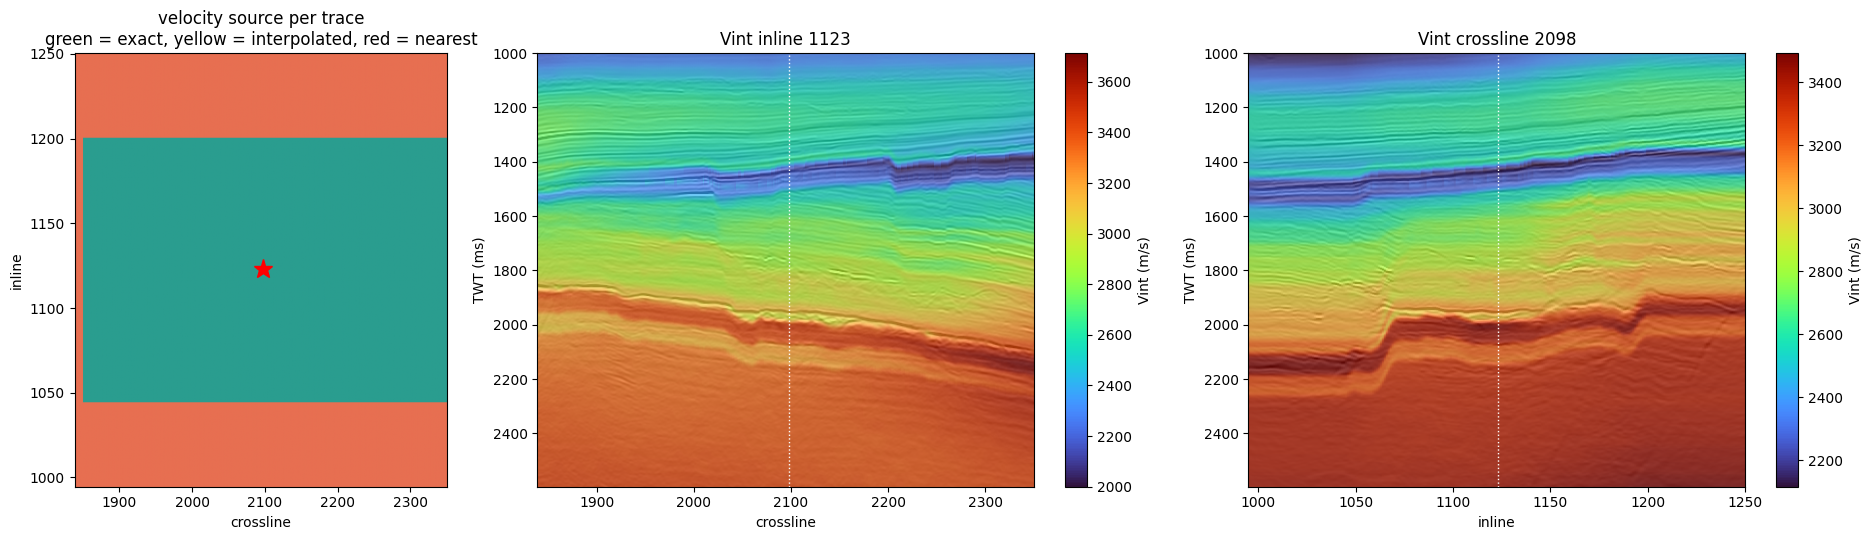

In [7]:
VEL = None
if VEL_PATH:
    from matplotlib.colors import ListedColormap
    VEL, vel_info = R.load_velocity_on_grid(VEL_PATH, G, VEL_IL_BYTE, VEL_XL_BYTE, match=VEL_MATCH)
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.2, 2, 2]})
    axes[0].imshow(vel_info["source"], origin="lower", aspect="auto", vmin=-0.5, vmax=2.5,
                   cmap=ListedColormap(["#2a9d8f", "#e9c46a", "#e76f51"]),
                   extent=(xlines[0] - .5, xlines[-1] + .5, ilines[0] - .5, ilines[-1] + .5))
    axes[0].plot(WELL_XL, WELL_IL, "r*", ms=14)
    axes[0].set_title("velocity source per trace\ngreen = exact, yellow = interpolated, red = nearest")
    axes[0].set_xlabel("crossline"); axes[0].set_ylabel("inline")
    for ax, vsec, ssec, ext, title, mark in (
            (axes[1], VEL[ci].T, cube[ci].T, (xlines[0], xlines[-1], samples[-1], samples[0]), f"Vint inline {ilines[ci]}", xlines[cx_]),
            (axes[2], VEL[:, cx_].T, cube[:, cx_].T, (ilines[0], ilines[-1], samples[-1], samples[0]), f"Vint crossline {xlines[cx_]}", ilines[ci])):
        im = ax.imshow(vsec, cmap="turbo", aspect="auto", extent=ext)
        v = np.percentile(np.abs(ssec), 99)
        ax.imshow(ssec, cmap="gray", aspect="auto", extent=ext, vmin=-v, vmax=v, alpha=0.3)
        ax.axvline(mark, color="w", lw=1, ls=":"); ax.set_title(title); ax.set_ylabel("TWT (ms)")
        plt.colorbar(im, ax=ax, label="Vint (m/s)")
    axes[1].set_xlabel("crossline"); axes[2].set_xlabel("inline")
    fig.tight_layout(); plt.show()
else:
    print("No VELOCITY_FILE set: skipping.")

## 4. Run RGT-Est

The model works on a fixed 400 × 512 × 512 grid. For your crop (256 inlines at 25 m, 512 crosslines at 12.5 m), the inline direction is stretched ×2, which makes the grid 12.5 m in both directions. The result is then resized back to your exact grid.

In [8]:
import time
import torch.nn as nn
import torch.nn.functional as F

def normalization(data):
    rng = np.max(data) - np.min(data)
    return (data - np.min(data)) / (rng + 1e-6)

def z_score_clip(data, clp_s=2.0):
    z = (data - np.mean(data)) / (np.std(data) + 1e-8)
    return normalization(np.clip(z, -clp_s, clp_s))

device = "cuda" if torch.cuda.is_available() else "cpu"
model = torch.jit.load(MODEL_PATH, map_location=device).eval()

from scipy.ndimage import grey_dilation
GRID = (400, 512, 512)
seis_norm = z_score_clip(cube) * 2 - 1

def guidance_volume(use):
    """Horizons → the model's guidance channel (same recipe as the authors' F3 demo)."""
    ids = np.zeros((NI, NX, NT), np.int16)
    for k, h in enumerate(use, 1):
        i, j = np.nonzero(np.isfinite(h["t"]))
        ids[i, j, np.clip(np.round((h["t"][i, j] - samples[0]) / dt).astype(int), 0, NT - 1)] = k
    ids = grey_dilation(ids, size=2)
    vol = np.zeros((NI, NX, NT), np.float32)
    for k, h in enumerate(use, 1):
        vol[ids == k] = (np.nanmean(h["t"]) - samples[0]) / dt / NT * 2 - 1
    return vol

def run_rgt(cube, guide=None):
    s = F.interpolate(torch.from_numpy(seis_norm.transpose(2, 0, 1).copy())[None, None], GRID, mode="trilinear")
    if guide is None:
        g = torch.zeros_like(s)
    else:
        g = F.interpolate(torch.from_numpy(guide.transpose(2, 0, 1).copy())[None, None], GRID, mode="nearest")
    x = torch.cat([s, g, (g != 0).float()], dim=1).to(device)
    t0 = time.time()
    with torch.no_grad(), torch.autocast(device_type=device):
        rgt = model(nn.ReplicationPad3d(8)(x))[:, :, 8:-8, 8:-8, 8:-8]
    print(f"inference took {time.time()-t0:.1f} s")
    out = F.interpolate(rgt.float(), (NT, NI, NX), mode="trilinear").cpu().numpy()[0, 0]
    del x, rgt
    if device == "cuda": torch.cuda.empty_cache()
    return z_score_clip(out).transpose(1, 2, 0).astype(np.float32)        # (inline, crossline, time), 0 = top

# ---- runs ----
print("Unguided:"); rgt_unguided = run_rgt(cube)
rgt_guided, rgt_loo = None, {}
if HZ:
    print(f"Guided with all {len(HZ)} horizons:"); rgt_guided = run_rgt(cube, guidance_volume(HZ))
    if len(HZ) >= 2:                                   # leave-one-out runs, for a fair score
        for h in HZ:
            print(f"Guided without {h['name']} (to test on it):")
            rgt_loo[h["name"]] = run_rgt(cube, guidance_volume([o for o in HZ if o is not h]))
rgt = rgt_guided if (rgt_guided is not None and USE_GUIDED) else rgt_unguided
print("Using the", "GUIDED" if rgt is rgt_guided else "UNGUIDED", "RGT for the outputs below. Shape:", rgt.shape)

Unguided:
inference took 6.9 s
Guided with all 2 horizons:
inference took 5.6 s
Guided without Ranger (to test on it):
inference took 4.5 s
Guided without Jubilee (to test on it):
inference took 4.5 s
Using the GUIDED RGT for the outputs below. Shape: (256, 512, 400)


## 4b. Does guidance help? (needs horizons)

For each horizon, we take the single RGT value that best matches it, trace the predicted horizon, and measure the vertical miss (ms) on every trace.

- **unguided:** the model saw no horizons.
- **held out:** the model was guided by the *other* horizon(s) but not this one. **This is the fair test.**
- **all guided:** the model was given this horizon too, so this only shows how closely it honours its input.

Hit rate = % of traces within 2 samples.

,horizon,unguided: error (ms),held out: error (ms),all guided: error (ms),unguided: hit %,held out: hit %,all guided: hit %
0,Ranger,9.2,8.4,7.3,57.6,61.8,59.8
1,Jubilee,42.3,38.9,2.9,20.6,21.1,93.8


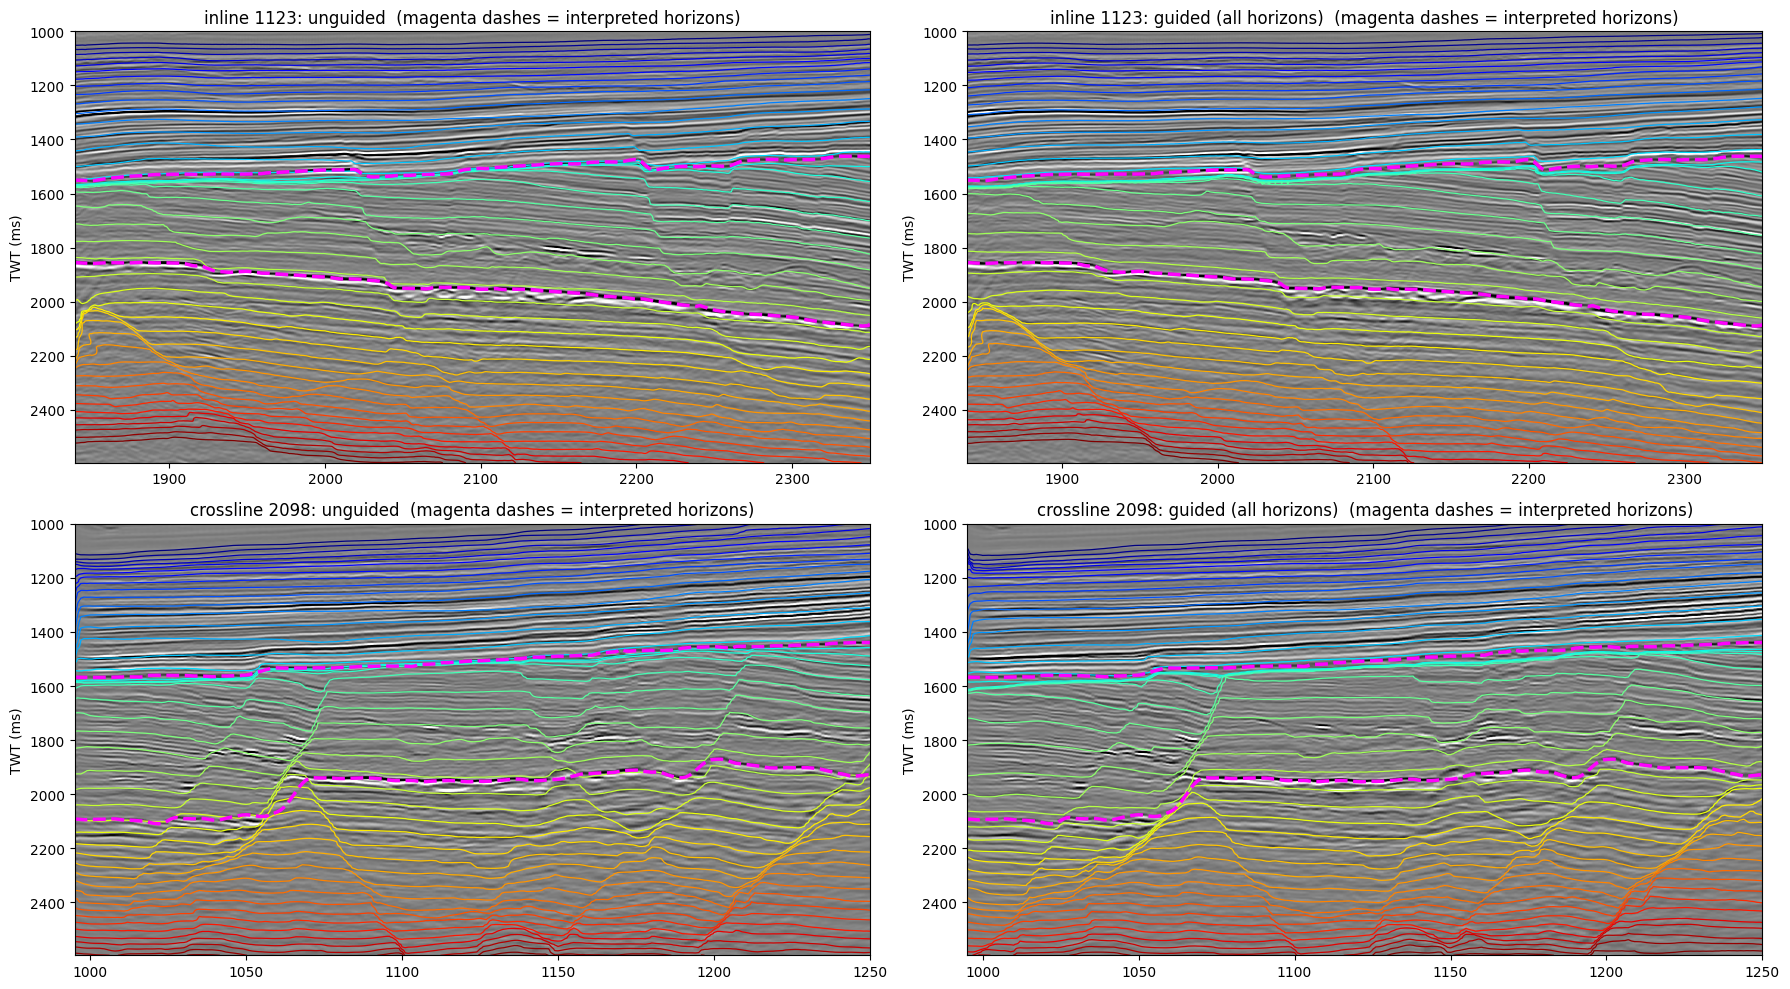

In [9]:
import pandas as pd
from rgt_helper import horizons_from_rgt

def horizon_errors(vol, hz_list):
    levels = []
    for h in hz_list:
        i, j = np.nonzero(np.isfinite(h["t"]))
        ti = np.clip(np.round((h["t"][i, j] - samples[0]) / dt).astype(int), 0, NT - 1)
        levels.append(np.median(vol[i, j, ti]))
    pred = samples[0] + horizons_from_rgt(sig=0.0, hu=np.array(levels), ux=vol) * dt
    out = []
    for h, p in zip(hz_list, pred):
        m = np.isfinite(h["t"]); err = np.abs(p[m] - h["t"][m])
        out.append((err.mean(), 100 * (err <= 2 * dt).mean()))
    return out

if not HZ:
    print("No horizons given: nothing to compare.")
else:
    res = {"unguided": horizon_errors(rgt_unguided, HZ), "all guided": horizon_errors(rgt_guided, HZ)}
    if rgt_loo:
        res["held out"] = [horizon_errors(rgt_loo[h["name"]], [h])[0] for h in HZ]
    cols = [c for c in ("unguided", "held out", "all guided") if c in res]
    table = pd.DataFrame({"horizon": [h["name"] for h in HZ]})
    for c in cols:
        table[f"{c}: error (ms)"] = [e for e, _ in res[c]]
    for c in cols:
        table[f"{c}: hit %"] = [r for _, r in res[c]]
    pd.options.display.float_format = "{:.1f}".format
    display(table)

    fig, axes = plt.subplots(2, 2, figsize=(18, 10))
    v = np.percentile(np.abs(cube), 99)
    for row, (sec_s, get, ext, title) in enumerate((
            (cube[ci].T, lambda vol: vol[ci].T, (xlines[0], xlines[-1], samples[-1], samples[0]), f"inline {ilines[ci]}"),
            (cube[:, cx_].T, lambda vol: vol[:, cx_].T, (ilines[0], ilines[-1], samples[-1], samples[0]), f"crossline {xlines[cx_]}"))):
        xs = xlines if row == 0 else ilines
        for col, (name, vol) in enumerate((("unguided", rgt_unguided), ("guided (all horizons)", rgt_guided))):
            ax = axes[row, col]
            ax.imshow(sec_s, cmap="gray", aspect="auto", vmin=-v, vmax=v, extent=ext)
            ax.contour(get(vol), levels=np.linspace(0.02, 0.98, 45), cmap="jet", linewidths=0.9,
                       extent=(ext[0], ext[1], ext[3], ext[2]))
            for h in HZ:
                ax.plot(xs, h["t"][ci] if row == 0 else h["t"][:, cx_], color="magenta", lw=2.5, ls="--")
            ax.set_title(f"{title}: {name}  (magenta dashes = interpreted horizons)"); ax.set_ylabel("TWT (ms)")
            ax.set_ylim(samples[-1], samples[0])
    fig.tight_layout(); plt.show()

## 5. Look at the result through the well

Seismic, RGT, and seismic with horizons (RGT contours). Check that the lines follow the reflectors, especially between the orange dashes.

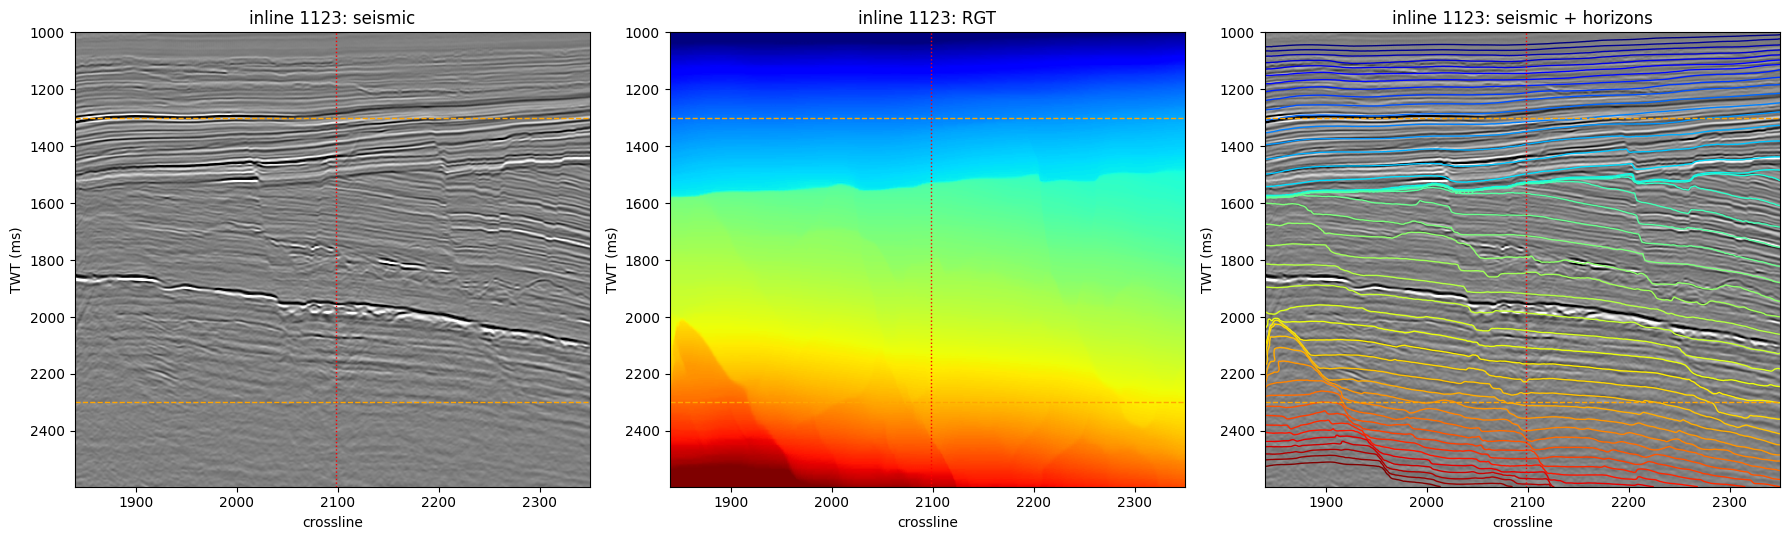

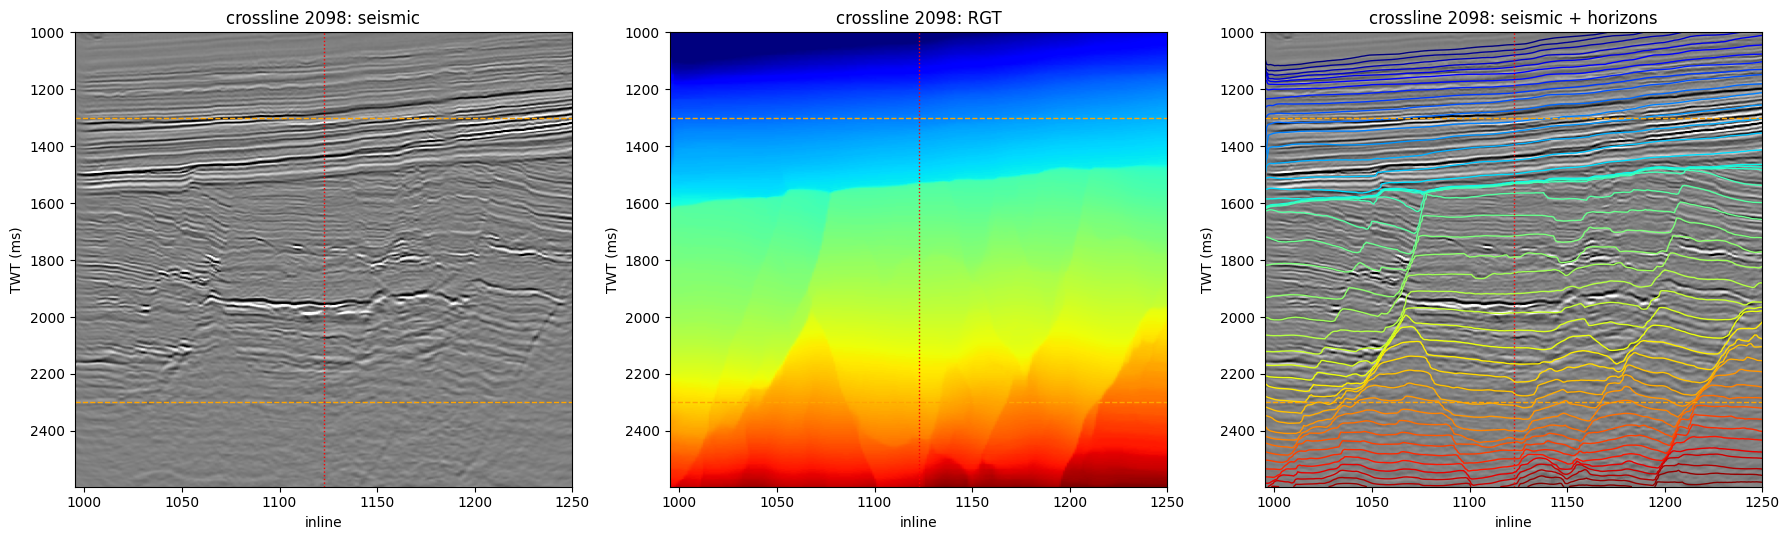

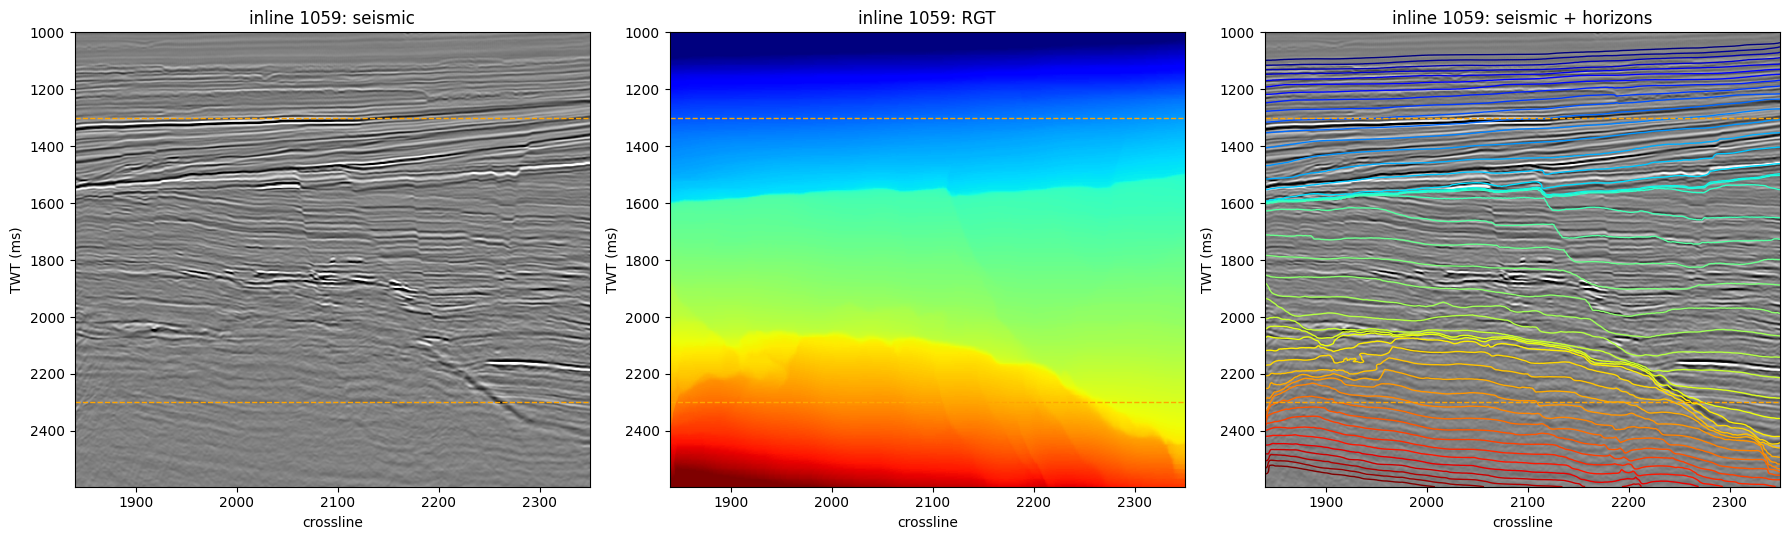

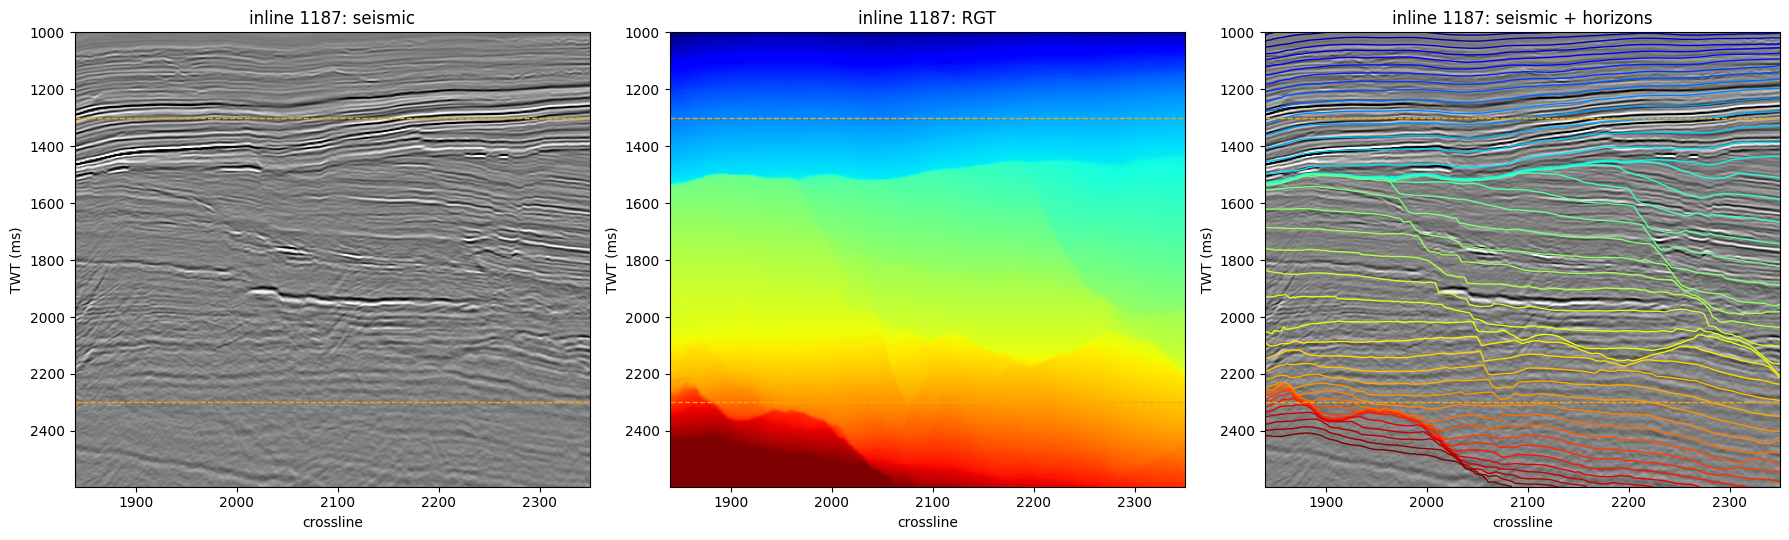

In [10]:
levels = np.linspace(0.02, 0.98, 45)

def three_panel(sec_s, sec_r, extent, title, xlabel, mark=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    v = np.percentile(np.abs(sec_s), 99)
    axes[0].imshow(sec_s, cmap="gray", aspect="auto", vmin=-v, vmax=v, extent=extent)
    axes[1].imshow(sec_r, cmap="jet", aspect="auto", extent=extent)
    axes[2].imshow(sec_s, cmap="gray", aspect="auto", vmin=-v, vmax=v, extent=extent)
    axes[2].contour(sec_r, levels=levels, cmap="jet", linewidths=1.0, extent=(extent[0], extent[1], extent[3], extent[2]))
    for ax, name in zip(axes, ("seismic", "RGT", "seismic + horizons")):
        ax.set_title(f"{title}: {name}"); ax.set_xlabel(xlabel); ax.set_ylabel("TWT (ms)")
        for t in INTERVAL_MS: ax.axhline(t, color="orange", lw=1, ls="--")
        if mark is not None: ax.axvline(mark, color="red", lw=1, ls=":")
        ax.set_ylim(samples[-1], samples[0])
    fig.tight_layout(); plt.show()

three_panel(cube[ci].T, rgt[ci].T, (xlines[0], xlines[-1], samples[-1], samples[0]),
            f"inline {ilines[ci]}", "crossline", WELL_XL if wx is not None else None)
three_panel(cube[:, cx_].T, rgt[:, cx_].T, (ilines[0], ilines[-1], samples[-1], samples[0]),
            f"crossline {xlines[cx_]}", "inline", WELL_IL if wi is not None else None)
for k in (NI // 4, 3 * NI // 4):
    three_panel(cube[k].T, rgt[k].T, (xlines[0], xlines[-1], samples[-1], samples[0]), f"inline {ilines[k]}", "crossline")

## 6. Save the RGT as SEG-Y (all trace headers copied from your input)

In [11]:
import shutil
stem = os.path.splitext(os.path.basename(SEGY_PATH))[0]
OUT = {}

def write_like_input(volume, out_path):
    """Copy the input SEG-Y, then replace every trace with the matching column of `volume`."""
    shutil.copyfile(SEGY_PATH, out_path)
    with segyio.open(out_path, "r+", ignore_geometry=True) as f:
        for k in range(n_tr):
            f.trace[k] = np.ascontiguousarray(volume[il_idx[k], xl_idx[k]], dtype=np.float32)
    print("wrote", out_path, f"({os.path.getsize(out_path)/1e6:.0f} MB)")
    return out_path

OUT["rgt"] = write_like_input(rgt_unguided, f"/content/{stem}_RGT.sgy")
if rgt_guided is not None:
    OUT["rgt_guided"] = write_like_input(rgt_guided, f"/content/{stem}_RGT_guided.sgy")
print("RGT values run from 0 (top of volume, youngest) to 1 (base, oldest).")
if VEL is not None:
    OUT["vint"] = write_like_input(VEL, f"/content/{stem}_Vint_on_grid.sgy")

wrote /content/Full_Stack_8_41_CROP_1793889427461_RGT.sgy (241 MB)
wrote /content/Full_Stack_8_41_CROP_1793889427461_RGT_guided.sgy (241 MB)
RGT values run from 0 (top of volume, youngest) to 1 (base, oldest).
wrote /content/Full_Stack_8_41_CROP_1793889427461_Vint_on_grid.sgy (241 MB)


## 7. Trace horizons and export them for RokDoc

Each horizon goes through one of `HORIZON_TIMES_AT_WELL` at the well, then follows the RGT across the volume.
Saved as ASCII columns: **Inline, Crossline, X, Y, TWT (ms)**.

horizon 1300 ms: at the well 1300 ms, range across the volume 1144 – 1428 ms
horizon 1550 ms: at the well 1550 ms, range across the volume 1472 – 1844 ms
horizon 1800 ms: at the well 1800 ms, range across the volume 1631 – 2091 ms
horizon 2050 ms: at the well 2050 ms, range across the volume 1787 – 2293 ms
horizon 2300 ms: at the well 2300 ms, range across the volume 2044 – 2524 ms
wrote /content/Full_Stack_8_41_CROP_1793889427461_horizons.txt and one file per horizon


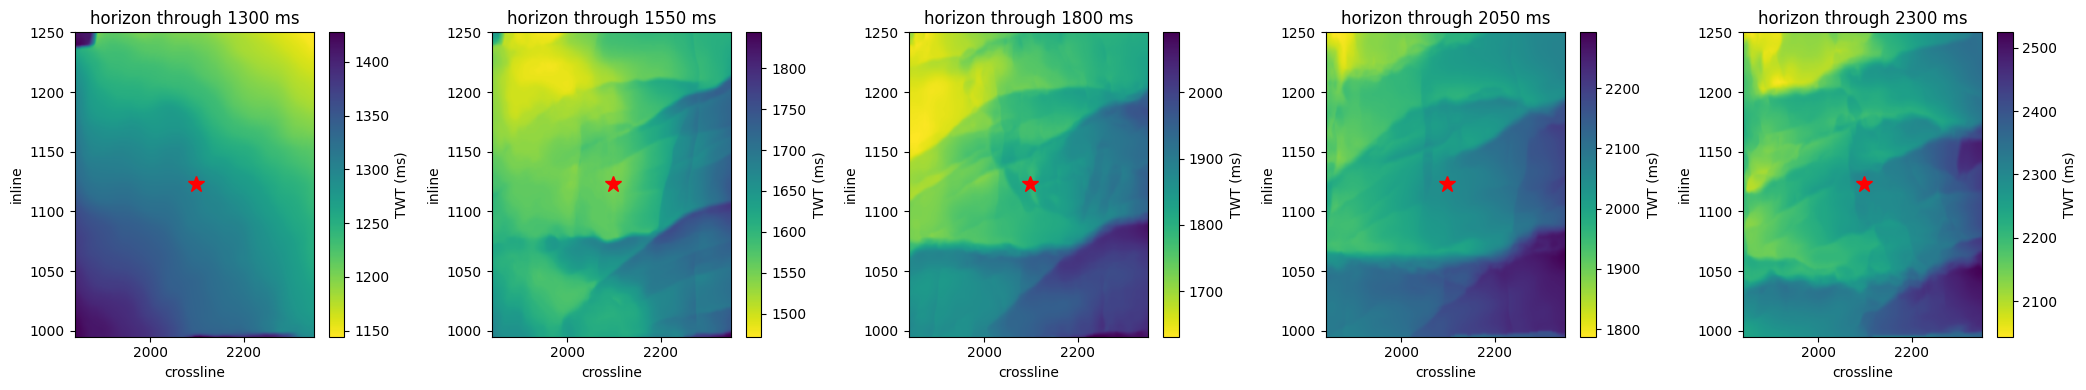

In [12]:
from rgt_helper import horizons_from_rgt
import pandas as pd

ref_i = wi if wi is not None else NI // 2
ref_x = wx if wx is not None else NX // 2
well_rgt = np.maximum.accumulate(rgt[ref_i, ref_x])                      # RGT down the well trace
levels_h = np.interp(HORIZON_TIMES_AT_WELL, samples, well_rgt)

hz_idx = horizons_from_rgt(sig=1.0, hu=levels_h, ux=rgt)                 # (n_horizons, inline, crossline), in samples
hz_ms = samples[0] + hz_idx * dt

II, XX = np.meshgrid(ilines, xlines, indexing="ij")
rows = []
for t_well, hz in zip(HORIZON_TIMES_AT_WELL, hz_ms):
    print(f"horizon {t_well} ms: at the well {hz[ref_i, ref_x]:.0f} ms, range across the volume {hz.min():.0f} – {hz.max():.0f} ms")
    rows.append(pd.DataFrame({"Horizon": f"RGT_{t_well}ms", "Inline": II.ravel(), "Crossline": XX.ravel(),
                              "X": X.ravel(), "Y": Y.ravel(), "TWT_ms": hz.ravel()}))
hz_table = pd.concat(rows)

OUT["horizons"] = f"/content/{stem}_horizons.txt"
hz_table.to_csv(OUT["horizons"], sep="\t", index=False, float_format="%.2f")
for t_well, g in hz_table.groupby("Horizon", sort=False):                 # also one file per horizon
    g.drop(columns="Horizon").to_csv(f"/content/{stem}_{t_well}.txt", sep="\t", index=False, float_format="%.2f")
print("wrote", OUT["horizons"], "and one file per horizon")

fig, axes = plt.subplots(1, len(hz_ms), figsize=(4.2 * len(hz_ms), 4))
for ax, hz, t_well in zip(np.atleast_1d(axes), hz_ms, HORIZON_TIMES_AT_WELL):
    im = ax.imshow(hz, cmap="viridis_r", aspect="auto", origin="lower",
                   extent=(xlines[0], xlines[-1], ilines[0], ilines[-1]))
    ax.plot(xlines[ref_x], ilines[ref_i], "r*", ms=12)
    ax.set_title(f"horizon through {t_well} ms"); ax.set_xlabel("crossline"); ax.set_ylabel("inline")
    plt.colorbar(im, ax=ax, label="TWT (ms)")
fig.tight_layout(); plt.show()

## 8. (Optional) RGT-guided low-frequency model

The well log is resampled to the seismic TWT samples and low-pass filtered (`LFM_CUTOFF_HZ`).

**With a velocity model:**
1. The velocity is converted to an AI background with a relation fitted at the well, `AI ≈ a · Vint^b`. No density assumption is needed, and it corrects any scaling bias in the velocities.
2. What the velocity can't explain at the well (log minus background) is spread along the RGT layers. Above and below the log it fades out over `LFM_TAPER_MS`, so the velocity background takes over.
3. The sum is low-pass filtered. It honours the well, follows the RGT layering, and varies laterally with the velocity model.

**Without a velocity model:** the low-passed log is spread along the RGT layers (constant along each layer), with end values held above and below the log.

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


log: 326 samples, TWT 1445 – 2337 ms, AI 5150 – 12183
Velocity → AI at the well:  AI ≈ 1.265 × Vint^1.076   (correlation 0.87 over the logged interval)


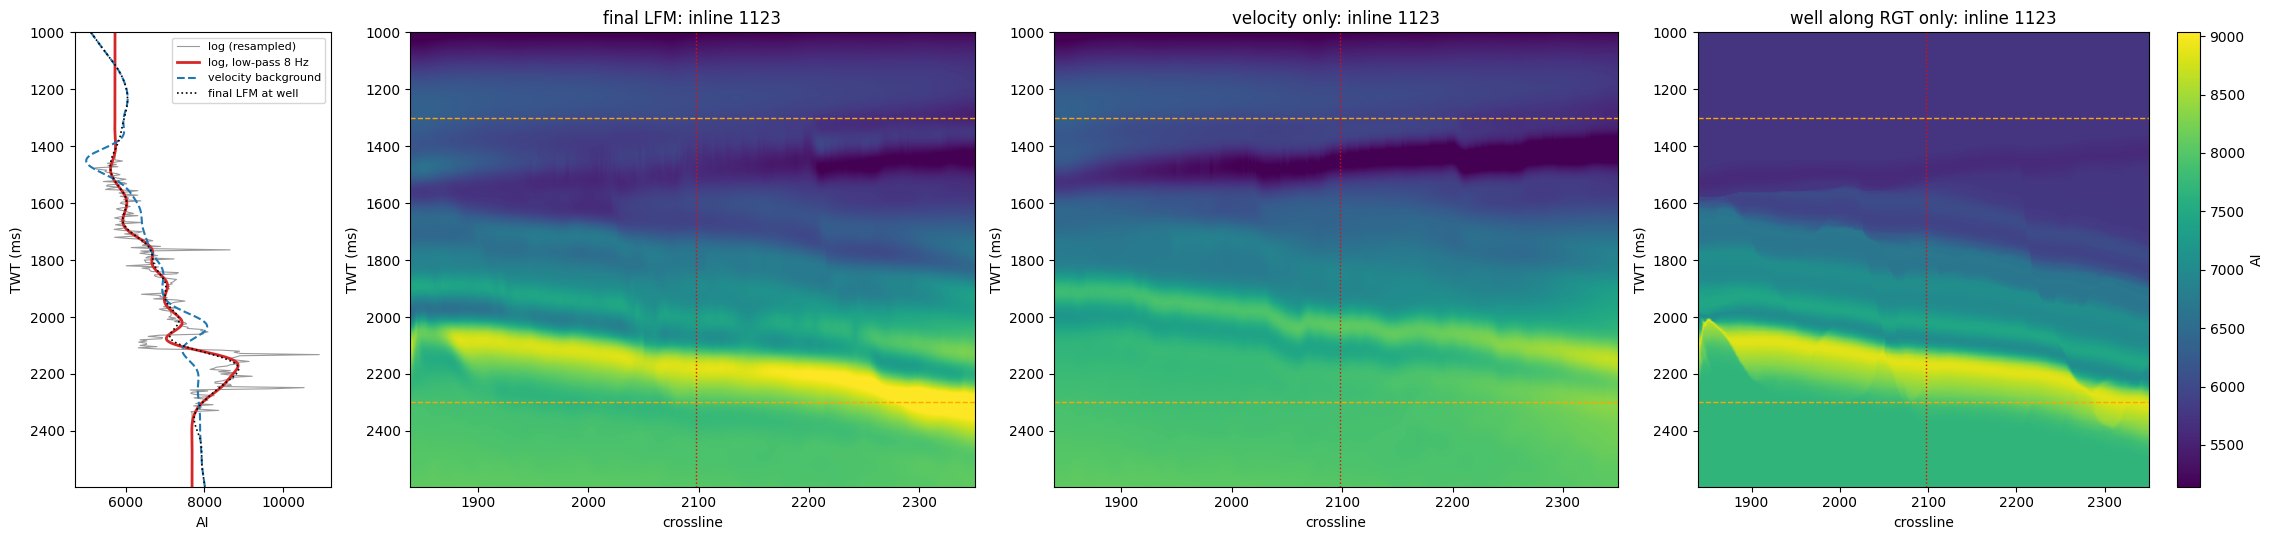

wrote /content/Full_Stack_8_41_CROP_1793889427461_LFM.sgy (241 MB)
wrote /content/Full_Stack_8_41_CROP_1793889427461_LFM_velocity_only.sgy (241 MB)
wrote /content/Full_Stack_8_41_CROP_1793889427461_LFM_step8.sgy (32 inlines × 64 crosslines, 3.8 MB)


In [13]:
from scipy.signal import butter, sosfiltfilt

if not LOG_PATH:
    print("No WELL_LOG_FILE set: skipping the LFM.")
elif wi is None:
    print("The well is outside the volume: skipping the LFM.")
else:
    raw = pd.read_excel(LOG_PATH, header=None) if LOG_PATH.lower().endswith((".xlsx", ".xls")) \
          else pd.read_csv(LOG_PATH, header=None, sep=None, engine="python")
    num = raw.apply(pd.to_numeric, errors="coerce").iloc[:, :2].dropna()
    log_t, log_ai = num.iloc[:, 0].to_numpy(float), num.iloc[:, 1].to_numpy(float)
    order = np.argsort(log_t); log_t, log_ai = log_t[order], log_ai[order]
    print(f"log: {len(log_t)} samples, TWT {log_t.min():.0f} – {log_t.max():.0f} ms, AI {log_ai.min():.0f} – {log_ai.max():.0f}")
    if log_t.max() < samples[0] or log_t.min() > samples[-1]:
        raise ValueError("The log's first column doesn't overlap the seismic TWT range. Is it in TWT (ms)?")

    ai = np.interp(samples, log_t, log_ai, left=np.nan, right=np.nan)
    valid = ~np.isnan(ai)
    first, last = np.argmax(valid), NT - 1 - np.argmax(valid[::-1])
    ai[:first], ai[last + 1:] = ai[first], ai[last]                         # hold end values outside the log
    sos = butter(4, LFM_CUTOFF_HZ, fs=1000.0 / dt, output="sos")
    ai_low = sosfiltfilt(sos, ai)

    well_r = np.maximum.accumulate(rgt[wi, wx]) + np.arange(NT) * 1e-7      # strictly increasing down the well
    lowpass = lambda v: sosfiltfilt(sos, v, axis=-1).astype(np.float32)
    lfm_rgt = np.interp(rgt, well_r, ai_low).astype(np.float32)             # well only, spread along RGT

    if VEL is None:
        lfm, lfm_vel, bg_well = lfm_rgt, None, None
        print("No velocity model: LFM = low-passed log spread along the RGT layers.")
    else:
        # 1. velocity → AI background, calibrated at the well:  AI ≈ a · Vint^b
        v_well = VEL[wi, wx].astype(float)
        b_exp, ln_a = np.polyfit(np.log(v_well[valid]), np.log(ai_low[valid]), 1)
        if not 0.3 < b_exp < 3:
            b_exp, ln_a = 1.0, np.mean(np.log(ai_low[valid]) - np.log(v_well[valid]))
            print("  (power-law fit unstable with this well: using AI = a · Vint)")
        a_coef = np.exp(ln_a)
        bg_well = a_coef * v_well ** b_exp
        r = np.corrcoef(ai_low[valid], bg_well[valid])[0, 1]
        print(f"Velocity → AI at the well:  AI ≈ {a_coef:.4g} × Vint^{b_exp:.3f}   (correlation {r:.2f} over the logged interval)")
        # 2. what the velocity doesn't explain at the well, faded out above/below the log, spread along RGT
        k = np.arange(NT)
        dist = np.where(valid, 0, np.minimum(np.abs(k - first), np.abs(k - last))) * dt
        taper = np.where(dist < LFM_TAPER_MS, 0.5 * (1 + np.cos(np.pi * dist / LFM_TAPER_MS)), 0.0)
        resid = (ai_low - bg_well) * taper
        bg = a_coef * VEL.astype(np.float32) ** b_exp
        lfm_vel = lowpass(bg)
        lfm = lowpass(bg + np.interp(rgt, well_r, resid))
        del bg

    show = [("final LFM", lfm)] + ([("velocity only", lfm_vel), ("well along RGT only", lfm_rgt)] if VEL is not None else [])
    fig, axes = plt.subplots(1, 1 + len(show), figsize=(5 + 6 * len(show), 5.5),
                             gridspec_kw={"width_ratios": [1] + [2.2] * len(show)})
    axes[0].plot(ai, samples, color="0.6", lw=0.8, label="log (resampled)")
    axes[0].plot(ai_low, samples, color="C3", lw=2, label=f"log, low-pass {LFM_CUTOFF_HZ} Hz")
    if VEL is not None:
        axes[0].plot(lfm_vel[wi, wx], samples, color="C0", lw=1.5, ls="--", label="velocity background")
    axes[0].plot(lfm[wi, wx], samples, color="k", lw=1.2, ls=":", label="final LFM at well")
    axes[0].set_ylim(samples[-1], samples[0]); axes[0].set_ylabel("TWT (ms)"); axes[0].set_xlabel("AI")
    axes[0].legend(fontsize=8)
    vmin, vmax = np.percentile(lfm[wi], [1, 99])
    for ax, (title, vol) in zip(axes[1:], show):
        im = ax.imshow(vol[wi].T, cmap="viridis", aspect="auto", vmin=vmin, vmax=vmax,
                       extent=(xlines[0], xlines[-1], samples[-1], samples[0]))
        ax.axvline(WELL_XL, color="red", lw=1, ls=":"); ax.set_title(f"{title}: inline {WELL_IL}")
        ax.set_xlabel("crossline"); ax.set_ylabel("TWT (ms)")
        for t in INTERVAL_MS: ax.axhline(t, color="orange", lw=1, ls="--")
    plt.colorbar(im, ax=axes[-1], label="AI")
    fig.tight_layout(); plt.show()

    OUT["lfm"] = write_like_input(lfm, f"/content/{stem}_LFM.sgy")
    if lfm_vel is not None:
        OUT["lfm_velocity_only"] = write_like_input(lfm_vel, f"/content/{stem}_LFM_velocity_only.sgy")

    # Decimated copy: every LFM_TRACE_STEP-th inline and crossline (well line included)
    sel_i = np.unique(np.r_[np.arange(wi % LFM_TRACE_STEP, NI, LFM_TRACE_STEP)])
    sel_x = np.unique(np.r_[np.arange(wx % LFM_TRACE_STEP, NX, LFM_TRACE_STEP)])
    if (trace_index[np.ix_(sel_i, sel_x)] < 0).any():
        print("Some decimated grid nodes have no trace in the input: skipping the decimated file.")
    else:
        spec = segyio.spec()
        spec.iline, spec.xline = il_byte, xl_byte
        spec.ilines, spec.xlines = ilines[sel_i], xlines[sel_x]
        spec.samples, spec.sorting, spec.format = samples, 2, 5
        out_path = f"/content/{stem}_LFM_step{LFM_TRACE_STEP}.sgy"
        with segyio.open(SEGY_PATH, ignore_geometry=True) as src, segyio.create(out_path, spec) as dst:
            dst.text[0] = src.text[0]
            n = 0
            for i in sel_i:
                for j in sel_x:
                    dst.header[n] = src.header[int(trace_index[i, j])]
                    dst.trace[n] = np.ascontiguousarray(lfm[i, j], dtype=np.float32)
                    n += 1
        OUT["lfm_decimated"] = out_path
        print("wrote", out_path, f"({len(sel_i)} inlines × {len(sel_x)} crosslines, {os.path.getsize(out_path)/1e6:.1f} MB)")

## 9. Download everything

Zips all outputs into one file and downloads it. If the browser blocks it, right-click the file in the Files panel and choose **Download**.

In [14]:
import zipfile
from google.colab import files
zip_path = f"/content/{stem}_RGT_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(glob.glob(f"/content/{stem}_*")):
        if not p.endswith(".zip") and os.path.getmtime(p) >= RUN_START:    # only this run's outputs
            z.write(p, os.path.basename(p)); print("  +", os.path.basename(p))
print(f"{zip_path} ({os.path.getsize(zip_path)/1e6:.0f} MB)")
files.download(zip_path)

  + Full_Stack_8_41_CROP_1793889427461_LFM.sgy
  + Full_Stack_8_41_CROP_1793889427461_LFM_step8.sgy
  + Full_Stack_8_41_CROP_1793889427461_LFM_velocity_only.sgy
  + Full_Stack_8_41_CROP_1793889427461_RGT.sgy
  + Full_Stack_8_41_CROP_1793889427461_RGT_1300ms.txt
  + Full_Stack_8_41_CROP_1793889427461_RGT_1550ms.txt
  + Full_Stack_8_41_CROP_1793889427461_RGT_1800ms.txt
  + Full_Stack_8_41_CROP_1793889427461_RGT_2050ms.txt
  + Full_Stack_8_41_CROP_1793889427461_RGT_2300ms.txt
  + Full_Stack_8_41_CROP_1793889427461_RGT_guided.sgy


KeyboardInterrupt: 